# Geldium Delinquency Risk: Exploratory Data Analysis
**Tata GenAI-Powered Data Analytics Job Simulation · Task 1**

Goal: check whether Geldium's 500-customer dataset is ready for a delinquency prediction model, fix the data quality problems, and find which variables actually signal risk.

**Headline:** the data is easy to clean (0.7% of cells missing), but no variable has even a weak relationship with delinquency, and two payment fields contradict each other for 86% of customers. Those two findings shape everything in Task 2.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.append(str(Path.cwd().parent / "src"))
from data_preprocessing import DelinquencyDataPreprocessor, MONTH_COLS

DATA = Path.cwd().parent / "data"
FIGS = Path.cwd().parent / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

BLUE, GREY, DARK = "#2f6fdb", "#bdbdb5", "#333333"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
                     "figure.dpi": 110})

raw = pd.read_excel(DATA / "Delinquency_prediction_dataset.xlsx")
print(f"{raw.shape[0]} records x {raw.shape[1]} columns")
raw.head()

500 records x 19 columns


,Customer_ID,Age,Income,Credit_Score,Credit_Utilization,Missed_Payments,Delinquent_Account,Loan_Balance,Debt_to_Income_Ratio,Employment_Status,Account_Tenure,Credit_Card_Type,Location,Month_1,Month_2,Month_3,Month_4,Month_5,Month_6
0,CUST0001,56,165580.0,398.0,0.390502,3,0,16310.0,0.317396,EMP,18,Student,Los Angeles,Late,Late,Missed,Late,Missed,Late
1,CUST0002,69,100999.0,493.0,0.312444,6,1,17401.0,0.196093,Self-employed,0,Standard,Phoenix,Missed,Missed,Late,Missed,On-time,On-time
2,CUST0003,46,188416.0,500.0,0.359930,0,0,13761.0,0.301655,Self-employed,1,Platinum,Chicago,Missed,Late,Late,On-time,Missed,Late
3,CUST0004,32,101672.0,413.0,0.371400,3,0,88778.0,0.264794,Unemployed,15,Platinum,Phoenix,Late,Missed,Late,Missed,Late,Late
4,CUST0005,60,38524.0,487.0,0.234716,2,0,13316.0,0.510583,Self-employed,11,Standard,Phoenix,Missed,On-time,Missed,Late,Late,Late


## 1. Data profile

In [2]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isnull().sum(),
    "missing_%": (raw.isnull().mean() * 100).round(1),
    "unique": raw.nunique(),
})
profile

,dtype,missing,missing_%,unique
Customer_ID,str,0,0.0,500
Age,int64,0,0.0,57
Income,float64,39,7.8,271
Credit_Score,float64,2,0.4,234
Credit_Utilization,float64,0,0.0,492
Missed_Payments,int64,0,0.0,7
Delinquent_Account,int64,0,0.0,2
Loan_Balance,float64,29,5.8,300
Debt_to_Income_Ratio,float64,0,0.0,487
Employment_Status,str,0,0.0,6


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,500.0,46.27,16.19,18.00,33.00,46.50,59.25,74.00
Income,461.0,108379.89,53662.72,15404.00,62295.00,107658.00,155734.00,199943.00
Credit_Score,498.0,577.72,168.88,301.00,418.25,586.00,727.25,847.00
Credit_Utilization,500.0,0.49,0.20,0.05,0.36,0.49,0.63,1.03
Missed_Payments,500.0,2.97,1.95,0.00,1.00,3.00,5.00,6.00
Delinquent_Account,500.0,0.16,0.37,0.00,0.00,0.00,0.00,1.00
Loan_Balance,471.0,48654.43,29395.54,612.00,23716.50,45776.00,75546.50,99620.00
Debt_to_Income_Ratio,500.0,0.30,0.09,0.10,0.23,0.30,0.36,0.55
Account_Tenure,500.0,9.74,5.92,0.00,5.00,10.00,15.00,19.00


## 2. Data quality issues

**Missing values:** three fields, 70 cells total.

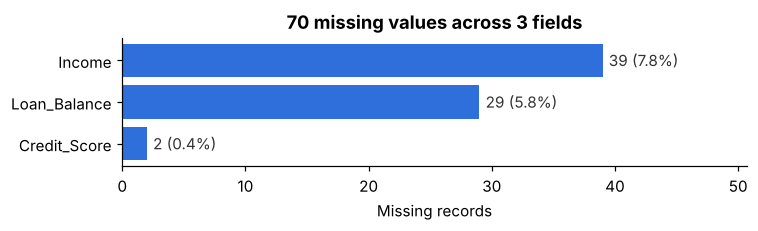

In [4]:
missing = raw.isnull().sum()
missing = missing[missing > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.barh(missing.index, missing.values, color=BLUE)
for i, v in enumerate(missing.values):
    ax.text(v + 0.5, i, f"{v} ({v / len(raw):.1%})", va="center", color=DARK)
ax.set_title(f"{missing.sum()} missing values across 3 fields")
ax.set_xlabel("Missing records")
ax.set_xlim(0, missing.max() * 1.3)
plt.tight_layout(); plt.savefig(FIGS / "missing_values.png", bbox_inches="tight"); plt.show()

**Inconsistent coding:** Employment_Status uses six spellings for four categories.

In [5]:
raw["Employment_Status"].value_counts()

Employment_Status
Unemployed       93
retired          87
Employed         82
EMP              81
Self-employed    80
employed         77
Name: count, dtype: int64

**Conflicting payment fields:** `Missed_Payments` should equal the number of "Missed" months in `Month_1`–`Month_6`. It doesn't for most customers, so at least one of these fields can't be trusted.

In [6]:
missed_in_history = (raw[MONTH_COLS] == "Missed").sum(axis=1)
mismatch = missed_in_history != raw["Missed_Payments"]
print(f"Mismatched records: {mismatch.sum()} of {len(raw)} ({mismatch.mean():.0%})")
print(f"Missed_Payments = 0 but history shows a missed month: {((raw['Missed_Payments'] == 0) & (missed_in_history > 0)).sum()}")
pd.crosstab(raw["Missed_Payments"], missed_in_history, rownames=["Missed_Payments field"], colnames=["'Missed' months in history"])

Mismatched records: 428 of 500 (86%)
Missed_Payments = 0 but history shows a missed month: 68


'Missed' months in history,0,1,2,3,4,5,6
Missed_Payments field,,,,,,,
0,9,20,21,18,7,2,0
1,5,13,21,11,2,2,0
2,3,22,32,17,3,2,0
3,7,19,25,14,12,1,0
4,9,19,28,22,4,1,0
5,2,18,25,19,3,0,1
6,5,13,25,15,3,0,0


**Other checks:** over-limit accounts, duplicates and class balance.

In [7]:
over = raw[raw["Credit_Utilization"] > 1]
print(f"Over-limit (>100% utilization): {len(over)} customers, {over['Delinquent_Account'].sum()} delinquent")
print(f"Duplicate rows: {raw.duplicated().sum()} · duplicate Customer_IDs: {raw['Customer_ID'].duplicated().sum()}")
print(f"Credit score range: {raw['Credit_Score'].min():.0f}-{raw['Credit_Score'].max():.0f} (valid 300-850)")
counts = raw["Delinquent_Account"].value_counts()
print(f"Class balance: {counts[1]} delinquent vs {counts[0]} not ({counts[1] / len(raw):.0%}); "
      f"predicting 'not delinquent' for everyone would be {counts[0] / len(raw):.0%} accurate")

Over-limit (>100% utilization): 4 customers, 0 delinquent
Duplicate rows: 0 · duplicate Customer_IDs: 0
Credit score range: 301-847 (valid 300-850)
Class balance: 80 delinquent vs 420 not (16%); predicting 'not delinquent' for everyone would be 84% accurate


## 3. Cleaning

| Field | Missing | Treatment | Why |
|---|---|---|---|
| Income | 39 (7.8%) | Median within each Employment_Status group | Keeps income differences between employment types |
| Loan_Balance | 29 (5.8%) | Overall median | No pattern in missingness; median is robust to the wide range |
| Credit_Score | 2 (0.4%) | Overall median | Two records; negligible effect |

Class balancing (SMOTE) is **not** done here. It belongs inside model training, on the training split only (see section 5).

In [8]:
pre = DelinquencyDataPreprocessor(DATA / "Delinquency_prediction_dataset.xlsx")
df = pre.run_full_pipeline(save_path=DATA / "Delinquency_cleaned.csv").get_processed_data()
pre.quality_report()

Loaded 500 rows x 19 columns
Employment_Status: 6 spellings -> 4 categories
Income: imputed 39 values with employment-group medians
Loan_Balance: imputed 29 values with the median
Credit_Score: imputed 2 values with the median
Over_Credit_Limit: 4 customers above 100% utilization
Added 6 payment-history features
Saved cleaned data to /home/claude/tata-genai-powered-data-analytics-project/data/Delinquency_cleaned.csv


{'records': 500,
 'columns': 26,
 'missing_values_before': 70,
 'missing_values_after': 0,
 'duplicates': 0,
 'delinquency_rate': 0.16,
 'class_counts': {0: 420, 1: 80}}

## 4. Risk factors

**Numeric variables:** correlation with delinquency, plus a Mann-Whitney test comparing delinquent and non-delinquent customers.

In [9]:
y = df["Delinquent_Account"]
numeric = ["Income", "Credit_Score", "Credit_Utilization", "Debt_to_Income_Ratio", "Age",
           "Loan_Balance", "Missed_Payments", "Account_Tenure"]
rows = []
for col in numeric:
    a, b = df.loc[y == 1, col], df.loc[y == 0, col]
    rows.append({"variable": col, "correlation": df[col].corr(y),
                 "mean_delinquent": a.mean(), "mean_not_delinquent": b.mean(),
                 "p_value": stats.mannwhitneyu(a, b).pvalue})
num_results = pd.DataFrame(rows).sort_values("correlation").round(3)
num_results

,variable,correlation,mean_delinquent,mean_not_delinquent,p_value
7,Account_Tenure,-0.040,9.200,9.843,0.422
6,Missed_Payments,-0.026,2.850,2.990,0.580
5,Loan_Balance,-0.005,48132.288,48555.136,0.973
4,Age,0.023,47.100,46.107,0.565
2,Credit_Utilization,0.034,0.507,0.489,0.391
3,Debt_to_Income_Ratio,0.034,0.306,0.297,0.493
1,Credit_Score,0.035,591.150,575.198,0.385
0,Income,0.044,113539.019,107321.817,0.351


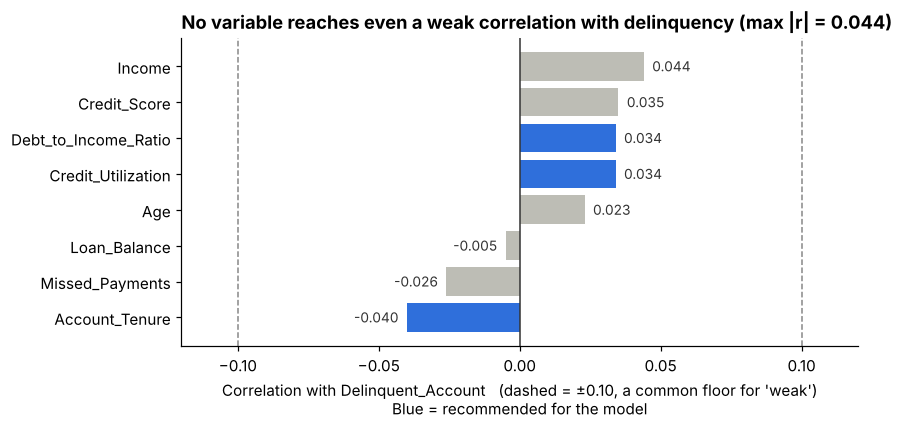

In [10]:
recommended = {"Credit_Utilization", "Debt_to_Income_Ratio", "Account_Tenure"}
r = num_results.sort_values("correlation")
fig, ax = plt.subplots(figsize=(8, 4))
colors = [BLUE if v in recommended else GREY for v in r["variable"]]
ax.barh(r["variable"], r["correlation"], color=colors)
for i, v in enumerate(r["correlation"]):
    ax.text(v + (0.003 if v >= 0 else -0.003), i, f"{v:.3f}", va="center",
            ha="left" if v >= 0 else "right", color=DARK, fontsize=9)
for x in (-0.1, 0.1):
    ax.axvline(x, color="#888", ls="--", lw=1)
ax.axvline(0, color=DARK, lw=1)
ax.set_xlim(-0.12, 0.12)
ax.set_title(f"No variable reaches even a weak correlation with delinquency (max |r| = {r['correlation'].abs().max():.3f})", loc="left")
ax.set_xlabel("Correlation with Delinquent_Account   (dashed = ±0.10, a common floor for 'weak')\nBlue = recommended for the model")
plt.tight_layout(); plt.savefig(FIGS / "correlations.png", bbox_inches="tight"); plt.show()

**Categorical segments:** delinquency rate by group against the 16% overall rate, with a chi-square test for each variable.

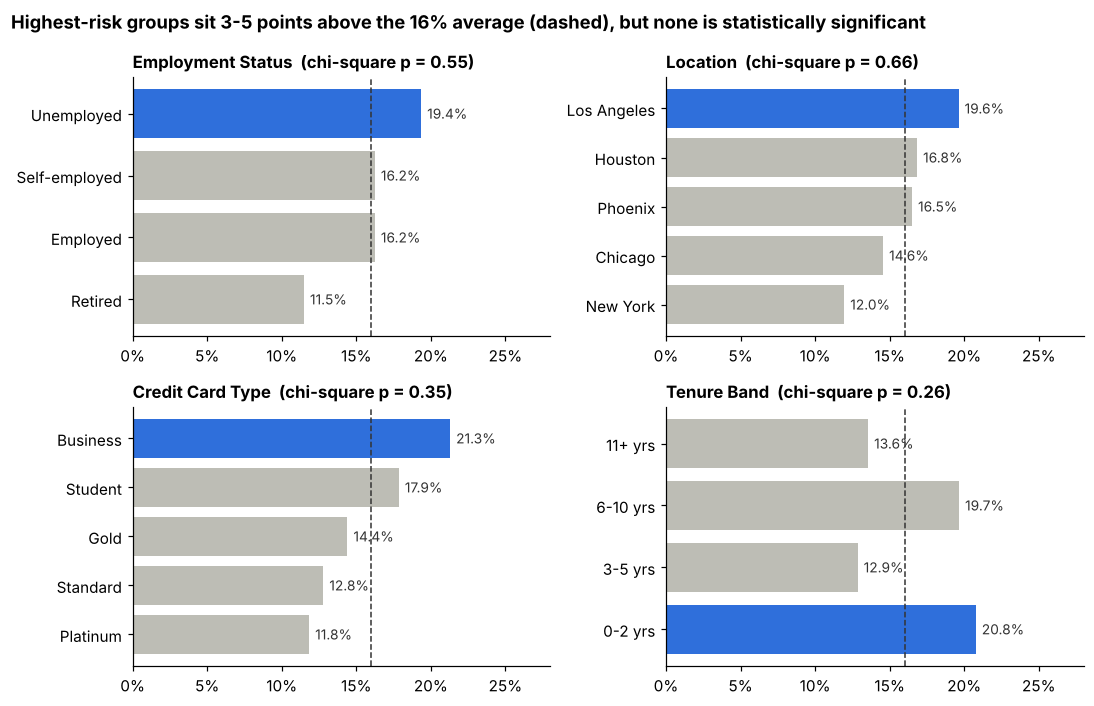

In [11]:
df["Tenure_Band"] = pd.cut(df["Account_Tenure"], [-1, 2, 5, 10, 20], labels=["0-2 yrs", "3-5 yrs", "6-10 yrs", "11+ yrs"])
segments = ["Employment_Status", "Location", "Credit_Card_Type", "Tenure_Band"]
overall = y.mean()

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, col in zip(axes.flat, segments):
    rates = df.groupby(col, observed=True)["Delinquent_Account"].mean()
    if col != "Tenure_Band":
        rates = rates.sort_values()
    p = stats.chi2_contingency(pd.crosstab(df[col], y))[1]
    ax.barh(rates.index.astype(str), rates.values, color=[BLUE if v == rates.max() else GREY for v in rates.values])
    ax.axvline(overall, color=DARK, ls="--", lw=1)
    for i, v in enumerate(rates.values):
        ax.text(v + 0.004, i, f"{v:.1%}", va="center", fontsize=9, color=DARK)
    ax.set_title(f"{col.replace('_', ' ')}  (chi-square p = {p:.2f})", loc="left", fontsize=11)
    ax.set_xlim(0, 0.28)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle(f"Highest-risk groups sit 3-5 points above the {overall:.0%} average (dashed), but none is statistically significant",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIGS / "segment_rates.png", bbox_inches="tight"); plt.show()

**What this shows**

- **Top 3 variables for the model:** Credit_Utilization and Debt_to_Income_Ratio (standard credit-stress signals, slightly higher among delinquent customers) and Account_Tenure (the strongest single correlation; accounts 0-2 years old are delinquent 20.8% of the time).
- **Highest-risk segments:** Business card holders (21.3%), new accounts (20.8%), Los Angeles (19.6%) and Unemployed (19.4%).
- **Surprises:** delinquent customers missed *fewer* payments on average, earn *more*, and have *higher* credit scores. All 4 over-limit customers are current.
- **Caveat:** every p-value is above 0.3, so these are leads to test in the model, not proven drivers.

## 5. Baseline check (preview of Task 2)

How much signal is there when all variables are combined? A logistic regression with SMOTE applied **inside each training fold** (the leak-free way) gives a quick answer.

In [12]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

features = df.drop(columns=["Customer_ID", "Delinquent_Account", "Tenure_Band"] + MONTH_COLS)
X = pd.get_dummies(features, drop_first=True).astype(float)
model = make_pipeline(StandardScaler(), SMOTE(random_state=42, k_neighbors=3), LogisticRegression(max_iter=2000))
cv = StratifiedKFold(5, shuffle=True, random_state=42)
auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
print(f"Cross-validated AUC: {auc.mean():.2f} (±{auc.std():.2f}); 0.50 = random guessing")

Cross-validated AUC: 0.49 (±0.04); 0.50 = random guessing


An AUC around 0.5 confirms the EDA: the current features carry almost no signal. For comparison, applying SMOTE to the full dataset *before* splitting (as an earlier version of this project did) lets synthetic copies of test customers into training and makes results look better than they are.

## 6. Next steps

1. Confirm with the data owner whether `Missed_Payments` or the monthly history is correct, then rebuild payment features from the trusted source.
2. Engineer combined features (for example high utilization × high DTI, new account × recent late payments).
3. Split before balancing; judge models on recall and AUC, not accuracy.
4. Ask for stronger signals: payment amounts, balance trends, months since last delinquency.